In [1]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils
from utils_worm import analysis_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import model_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(analysis_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
file_id = 19
model_variant = 'ss'

selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

neuron_labels = ['RMDDR', 'VB02', 'SMDDL', 'SMDDR', 'SIADR', 'DD01'] + ['AVBL', 'AVAR']

In [4]:
filename, traces, eigenworms, discrete_states, (continuous_behaviors, kymograph) = analysis_utils.read_data(file_id)
neuron_labels = [label for label in neuron_labels if label in traces.columns]

In [5]:
bom_params, hgm_params = analysis_utils.read_models(filename, model_variant, manual=False)

((bom_man, bom_rec, bom_res, bom_pres, bom_resss, bom_bss),
 (hgm_man, hgm_rec, hgm_res, hgm_pres, hgm_resss, hgm_bss)) = analysis_utils.read_predictions(filename, model_variant, manual=False)

# manifold

In [6]:
pca_modes, _, _, pca_vars_expl = train_utils.get_manifolds_pca([traces], scale=False, n_pc=hgm_man[0].values.shape[1])
cca_modes, _, _, _, _, _, cca_vars_expl, cca_vars_expl_rs = train_utils.get_manifolds_cca([traces], [discrete_states[selection_bhl]], scale=False, n_cv=hgm_man[0].values.shape[1], n_pc=discrete_states[selection_bhl].values.shape[1])

In [7]:
bom_manifolds, bom_manifold_vars_expl = analysis_utils.postprocess_manifold(bom_man, traces, bom_params)
hgm_manifolds, hgm_manifold_vars_expl = analysis_utils.postprocess_manifold(bom_man, traces, bom_params)

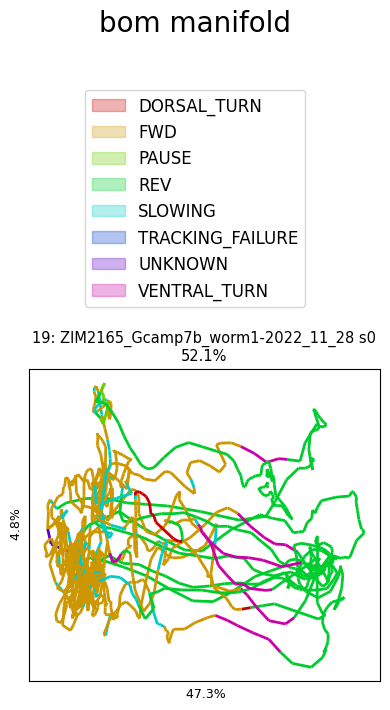

52.1%


In [8]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(len(bom_manifolds))],
						  [bom_manifolds[s] for s in range(len(bom_manifolds))],
						  [discrete_states for s in range(len(bom_manifolds))],
						  bom_manifold_vars_expl, None,
						  title='bom manifold', plots_per_row=len(bom_manifolds), top_space=3.5,
						  save_path=None)

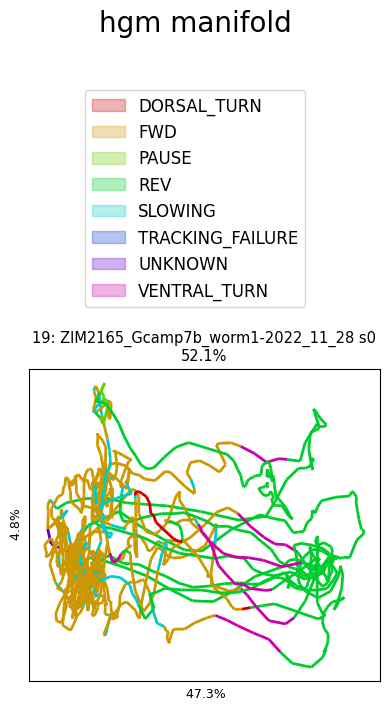

52.1%


In [9]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(len(hgm_manifolds))],
						  [hgm_manifolds[s] for s in range(len(hgm_manifolds))],
						  [discrete_states for s in range(len(hgm_manifolds))],
						  hgm_manifold_vars_expl, None,
						  title='hgm manifold', plots_per_row=len(hgm_manifolds), top_space=3.5,
						  save_path=None)

# RES MODES

In [10]:
pca_pres = PCA(n_components=bom_pres[0].values.shape[1])
pca_pres.fit(bom_pres[0].values)

,n_components,121
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


np.float32(0.9999997)

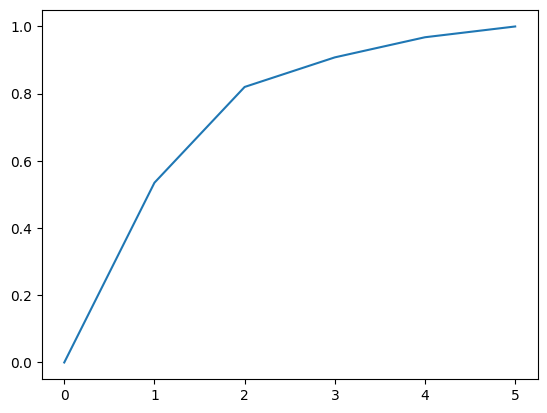

In [11]:
modes = 5

plt.plot([sum(pca_pres.explained_variance_ratio_[:k]) for k in range(modes+1)])
sum(pca_pres.explained_variance_ratio_[:modes+1])

In [12]:
cols = [f'Mode {i+1}' for i in range(hgm_pres[0].shape[1])]
cols_plot = cols[:modes]

bom_pres_modes = [pd.DataFrame(pca_pres.transform(bom_pres[0].values), columns=cols)]
hgm_pres_modes = [pd.DataFrame(pca_pres.transform(hgm_pres[0].values), columns=cols)]

bom_res_modes = [pd.DataFrame(pca_pres.transform(bom_res[0].values), columns=cols)]
hgm_res_modes = [pd.DataFrame(pca_pres.transform(hgm_res[0].values), columns=cols)]

# MANIFOLD COLORING

In [13]:
sigmoid = lambda x: 1 / (1 + np.exp(-x))

In [14]:
hgm_man_zs = (hgm_man[0].values - hgm_man[0].values.mean(axis=0)) / np.where((N_std := hgm_man[0].values.std(axis=0)) == 0.0, 1.0, N_std)
WM = hgm_params[0]['model']['WM']
VB = hgm_params[0]['model']['VB']

gating_space = sigmoid(hgm_man_zs @ WM) @ VB
gating_space_modes = [pd.DataFrame(pca_pres.transform(gating_space), columns=cols)]

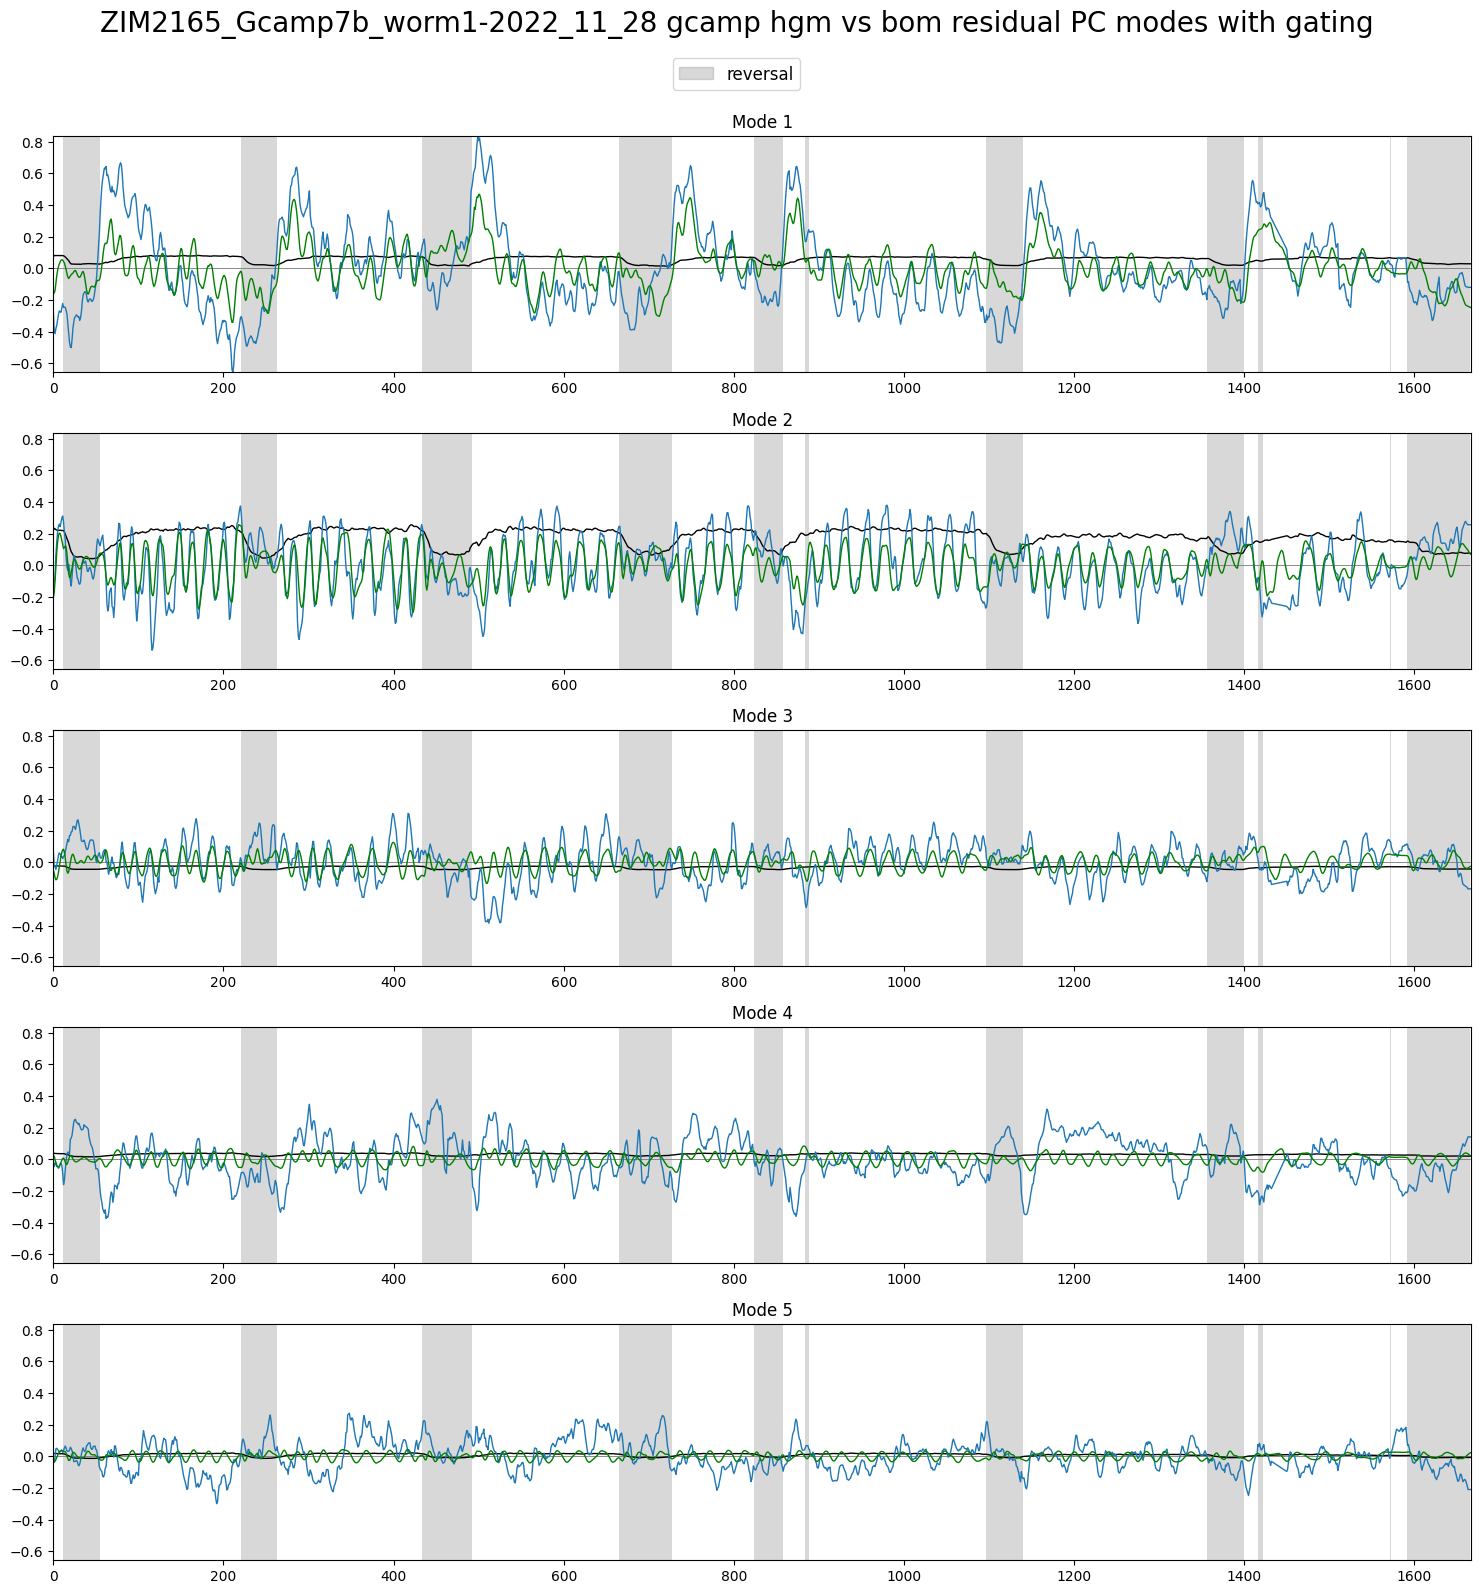

In [15]:
# max_x = 500
max_x = bom_pres[0].values.shape[0]

plot_utils.plot_traces_splits_pairs(
	[hgm_res_modes[0].loc[:max_x, cols_plot], hgm_pres_modes[0].loc[:max_x, cols_plot]],
	# [bom_res_modes[0].loc[:max_x, cols_plot], bom_pres_modes[0].loc[:max_x, cols_plot]],
	None,
	gating_space_modes[0].loc[:max_x, cols_plot],
	discrete_states.loc[:max_x, ['REV']], label='reversal',
	title=f'{filename} gcamp hgm vs bom residual PC modes with gating', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_RES'

In [16]:
# # max_x = 500
# max_x = bom_pres[0].values.shape[0]
#
# plot_utils.plot_traces_splits(
# 	[hgm_res_modes[0].loc[:max_x, cols_plot]],
# 	[bom_res_modes[0].loc[:max_x, cols_plot]],
# 	gating_space_modes[0].loc[:max_x, cols_plot],
# 	discrete_states.loc[:max_x, ['REV']], label='reversal',
# 	title=f'{filename} gcamp hgm vs bom residual PC modes with gating', ylimits=None, plots_per_row=1,
# 	save_path=None)  #'../../out/plots/GCAMP_RES'

In [17]:
# # max_x = 500
# max_x = bom_pres[0].values.shape[0]
#
# plot_utils.plot_traces_splits(
# 	[hgm_pres_modes[0].loc[:max_x, cols_plot]],
# 	[bom_pres_modes[0].loc[:max_x, cols_plot]],
# 	gating_space_modes[0].loc[:max_x, cols_plot],
# 	discrete_states.loc[:max_x, ['REV']], label='reversal',
# 	title=f'{filename} gcamp hgm gating space PC modes', ylimits=None, plots_per_row=1,
# 	save_path=None)  #'../../out/plots/GCAMP_RES'

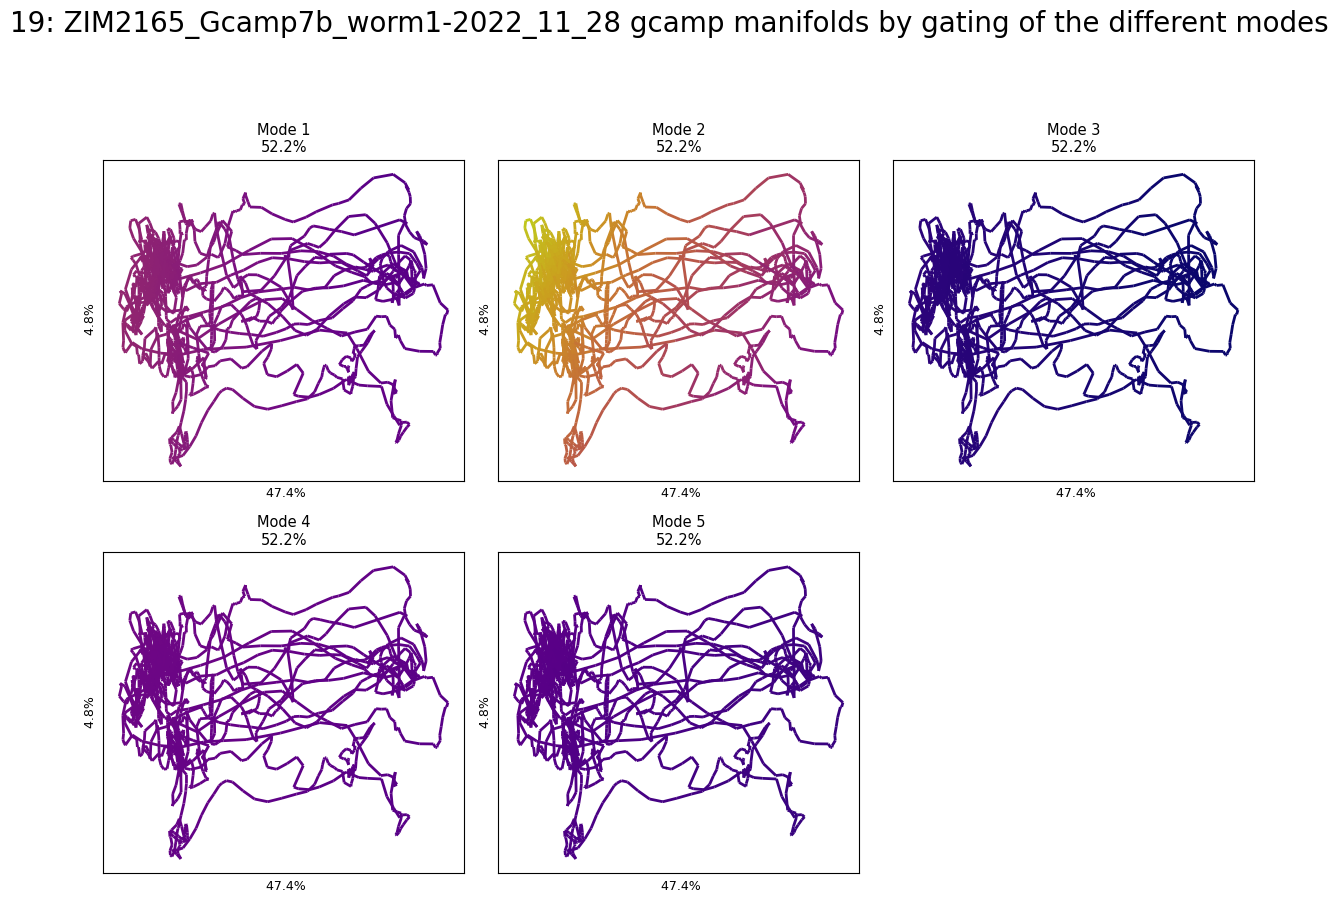

52.2%


In [18]:
resss_ids = [hgm_resss[0].columns.get_loc(ss) for ss in hgm_resss[0].columns]

sigmoid_terms = list()
manifold_terms = list()
vars_explained = list()

for resss_id in resss_ids:
	hgm_man_zs = (hgm_man[0].values - hgm_man[0].values.mean(axis=0)) / np.where((N_std := hgm_man[0].values.std(axis=0)) == 0.0, 1.0, N_std)
	WM = hgm_params[0]['model']['WM'][:, resss_id]
	sigmoid_term = sigmoid(hgm_man_zs @ WM)
	sigmoid_terms.append(pd.DataFrame(data=sigmoid_term))

	decode = lambda X: X @ model_utils.orthonormalize_qr(hgm_params[0]['model']['UN']).T
	manifold_term, var_explained = train_utils.postprocess_manifold(hgm_man[0].values, traces.values, decode, scale=False, align=True)
	manifold_terms.append(pd.DataFrame(data=manifold_term, columns=hgm_man[0].columns))
	vars_explained.append(var_explained)

plot_utils.plot_manifolds_gradient([f'Mode {ss+1}' for ss in range(modes)],
								   [manifold_terms[0]] * modes,
								   [gating_space_modes[0][[f'Mode {ss+1}']] for ss in range(modes)],
								   vars_explained * modes, None,
								   title=f'{str(file_id)}: {filename} gcamp manifolds by gating of the different modes',
								   plots_per_row=3, top_space=1,
								   save_path=None)

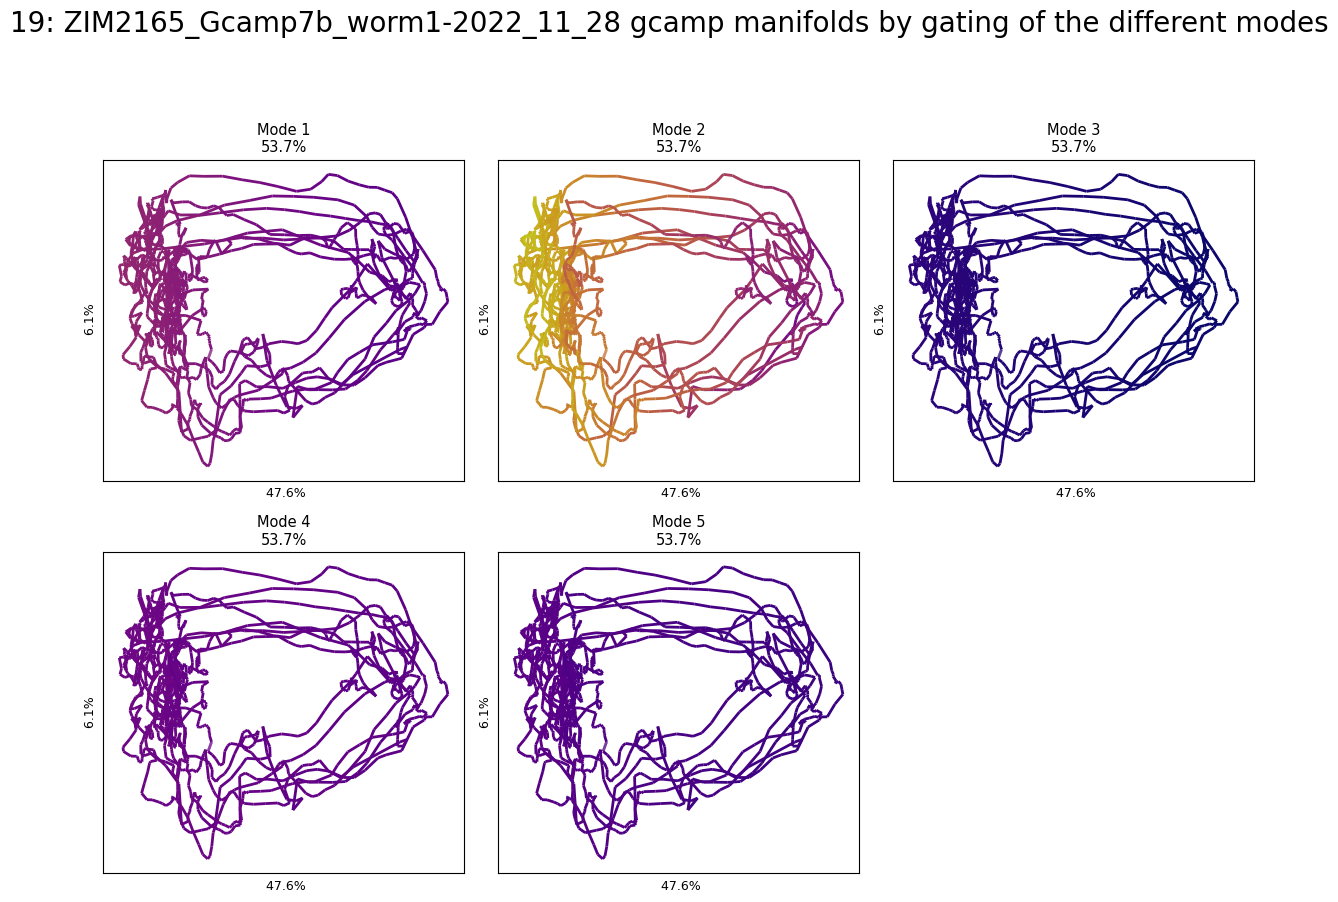

53.7%


In [19]:
plot_utils.plot_manifolds_gradient([f'Mode {ss+1}' for ss in range(modes)],
								   [pca_modes[0]] * modes,
								   [gating_space_modes[0][[f'Mode {ss+1}']] for ss in range(modes)],
								   pca_vars_expl * modes, None,
								   title=f'{str(file_id)}: {filename} gcamp manifolds by gating of the different modes',
								   plots_per_row=3, top_space=1,
								   save_path=None)

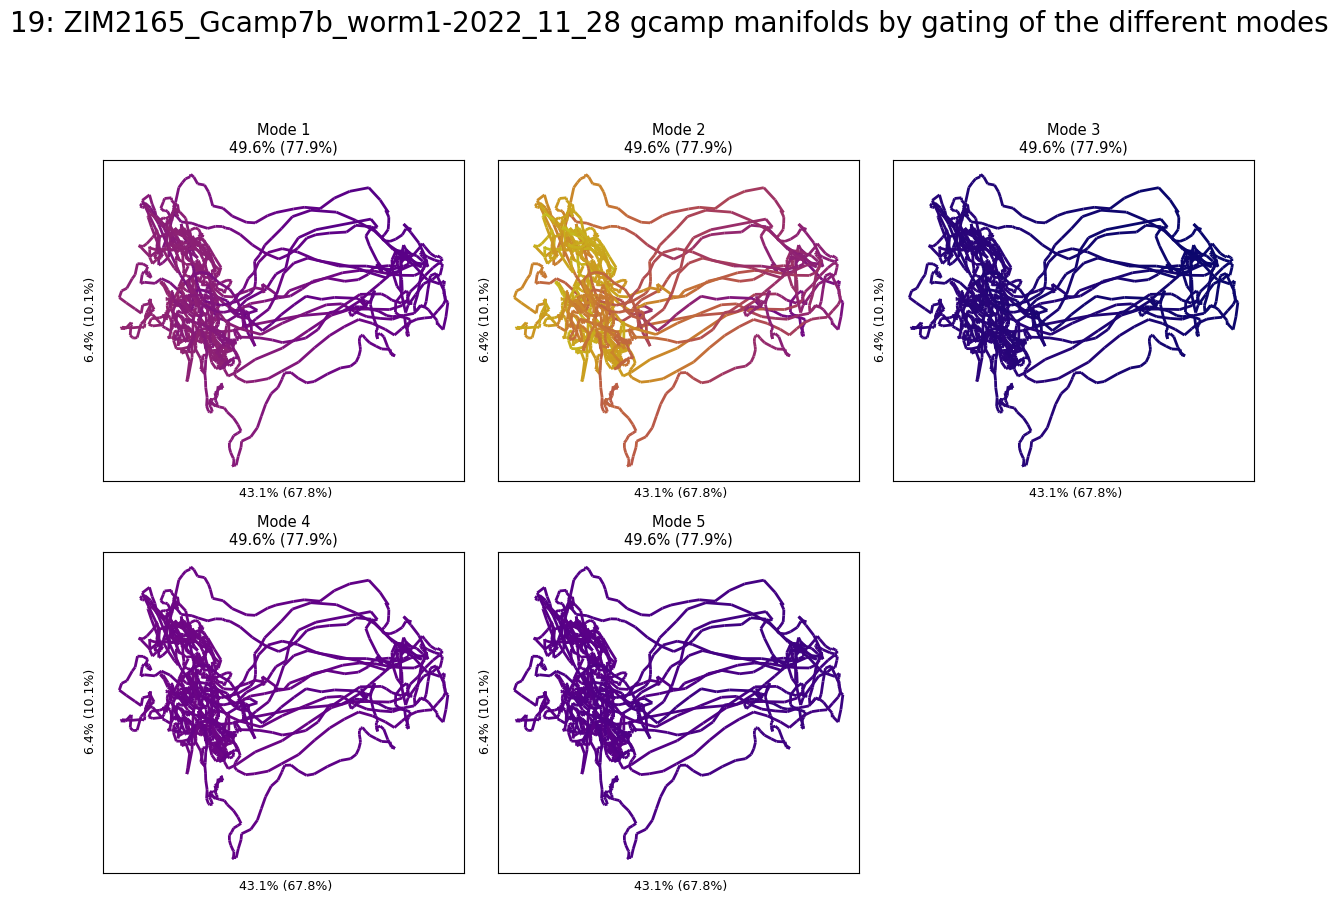

49.6% (77.9%)


In [20]:
plot_utils.plot_manifolds_gradient([f'Mode {ss+1}' for ss in range(modes)],
								   [cca_modes[0]] * modes,
								   [gating_space_modes[0][[f'Mode {ss+1}']] for ss in range(modes)],
								   cca_vars_expl * modes, cca_vars_expl_rs * modes,
								   title=f'{str(file_id)}: {filename} gcamp manifolds by gating of the different modes',
								   plots_per_row=3, top_space=1,
								   save_path=None)

# traces

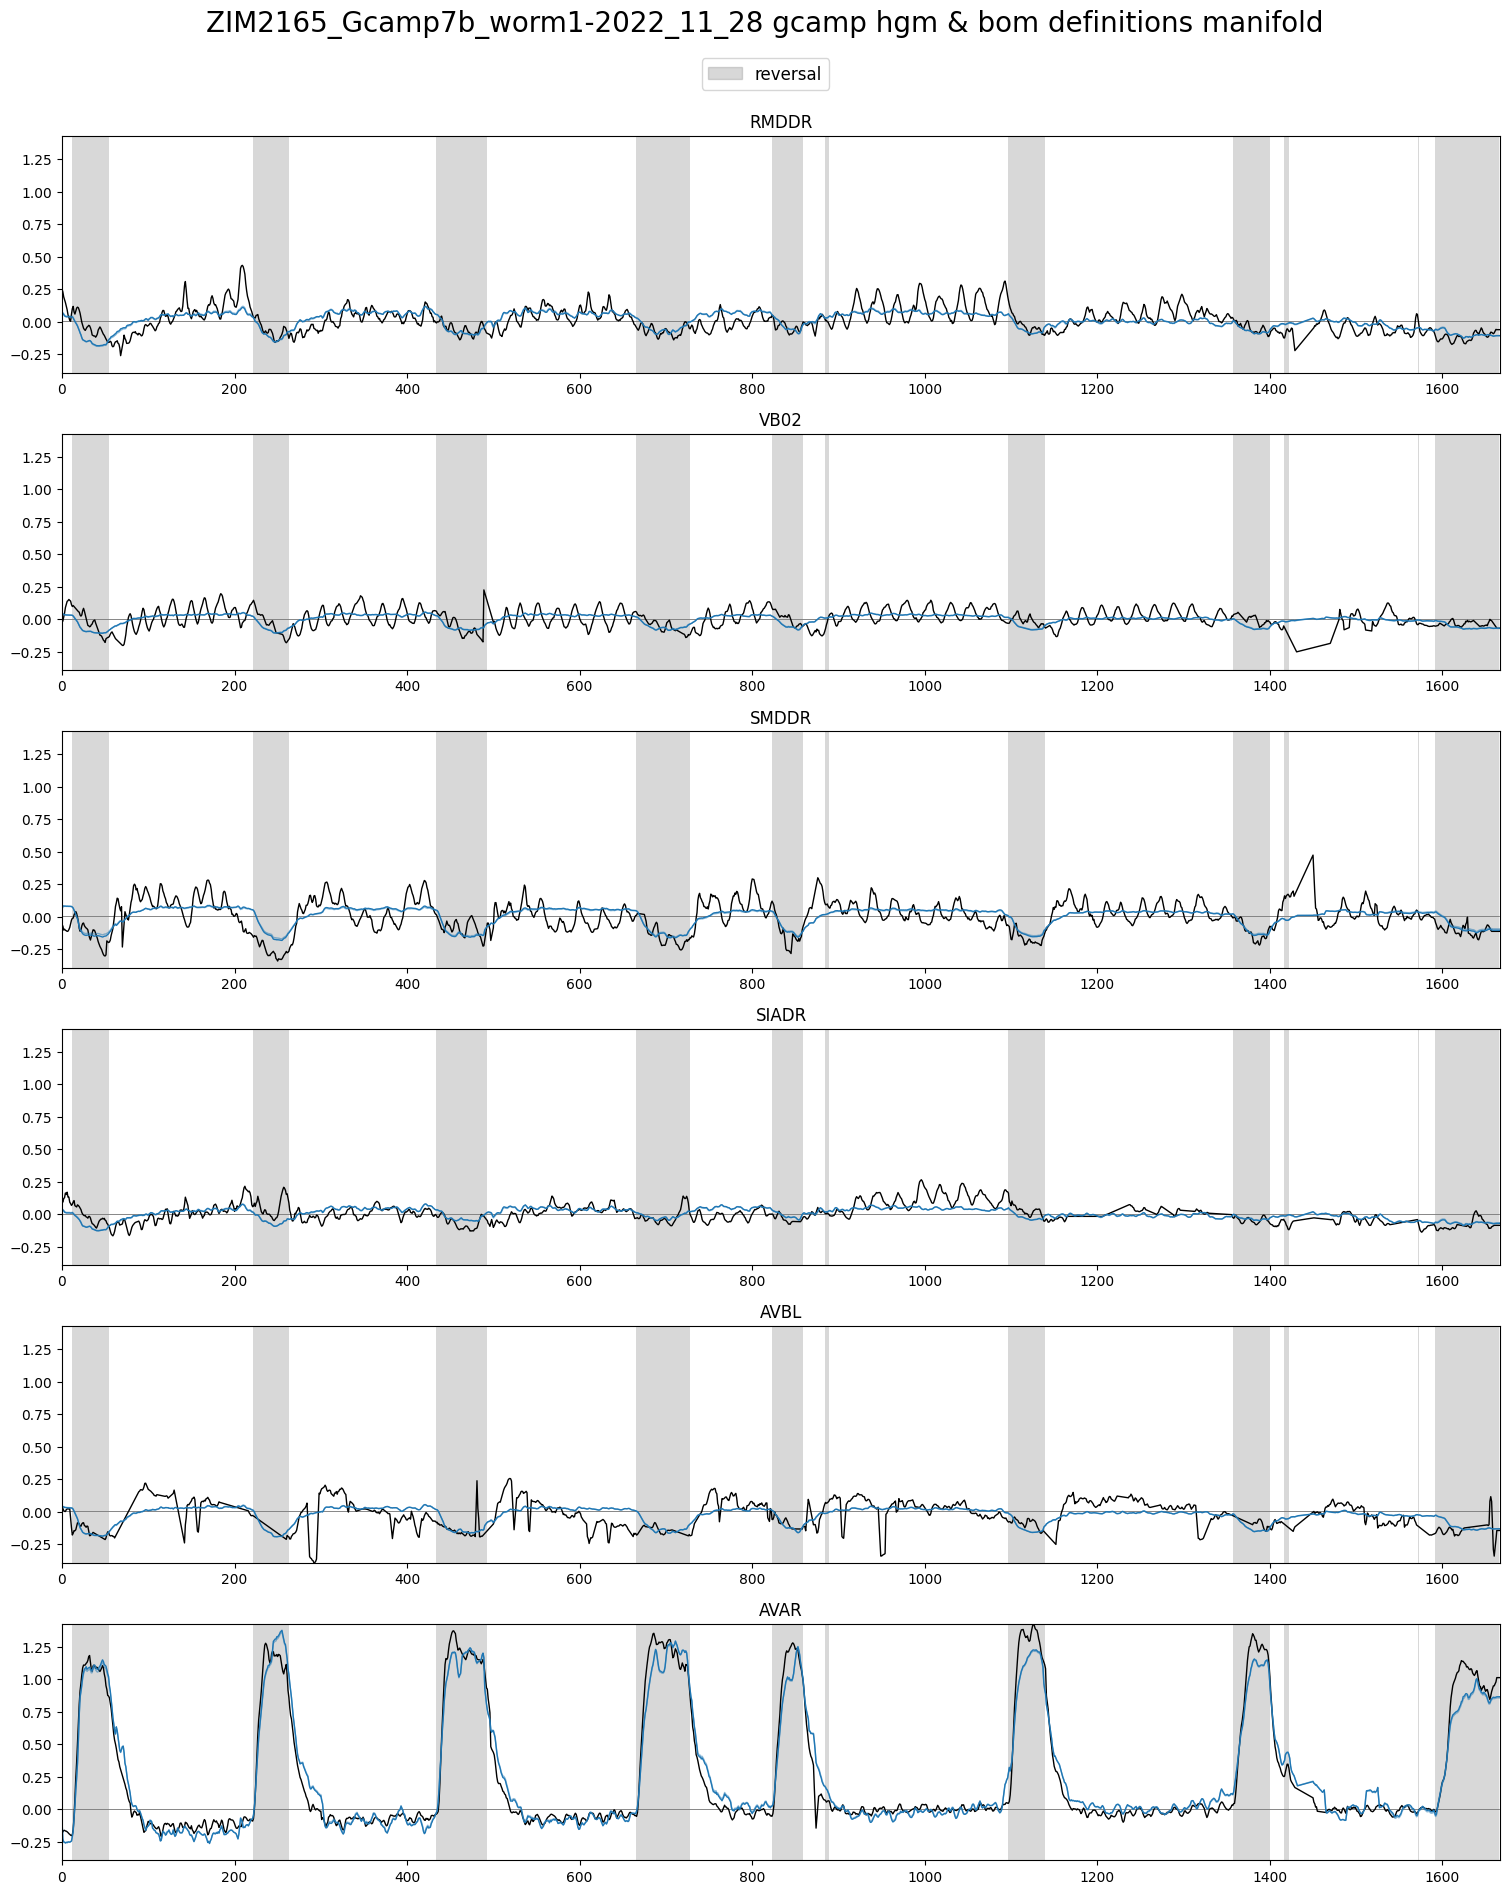

In [21]:
# max_x = 500
max_x = traces.values.shape[0]

plot_utils.plot_traces_splits(
	[hgm_rec[i].loc[:max_x, neuron_labels] for i in range(len(hgm_rec))],
	[bom_rec[i].loc[:max_x, neuron_labels] for i in range(len(hgm_rec))],
	traces.loc[:max_x, neuron_labels],
	discrete_states.loc[:max_x, ['REV']], label='reversal',
	title=f'{filename} gcamp hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_MAN'

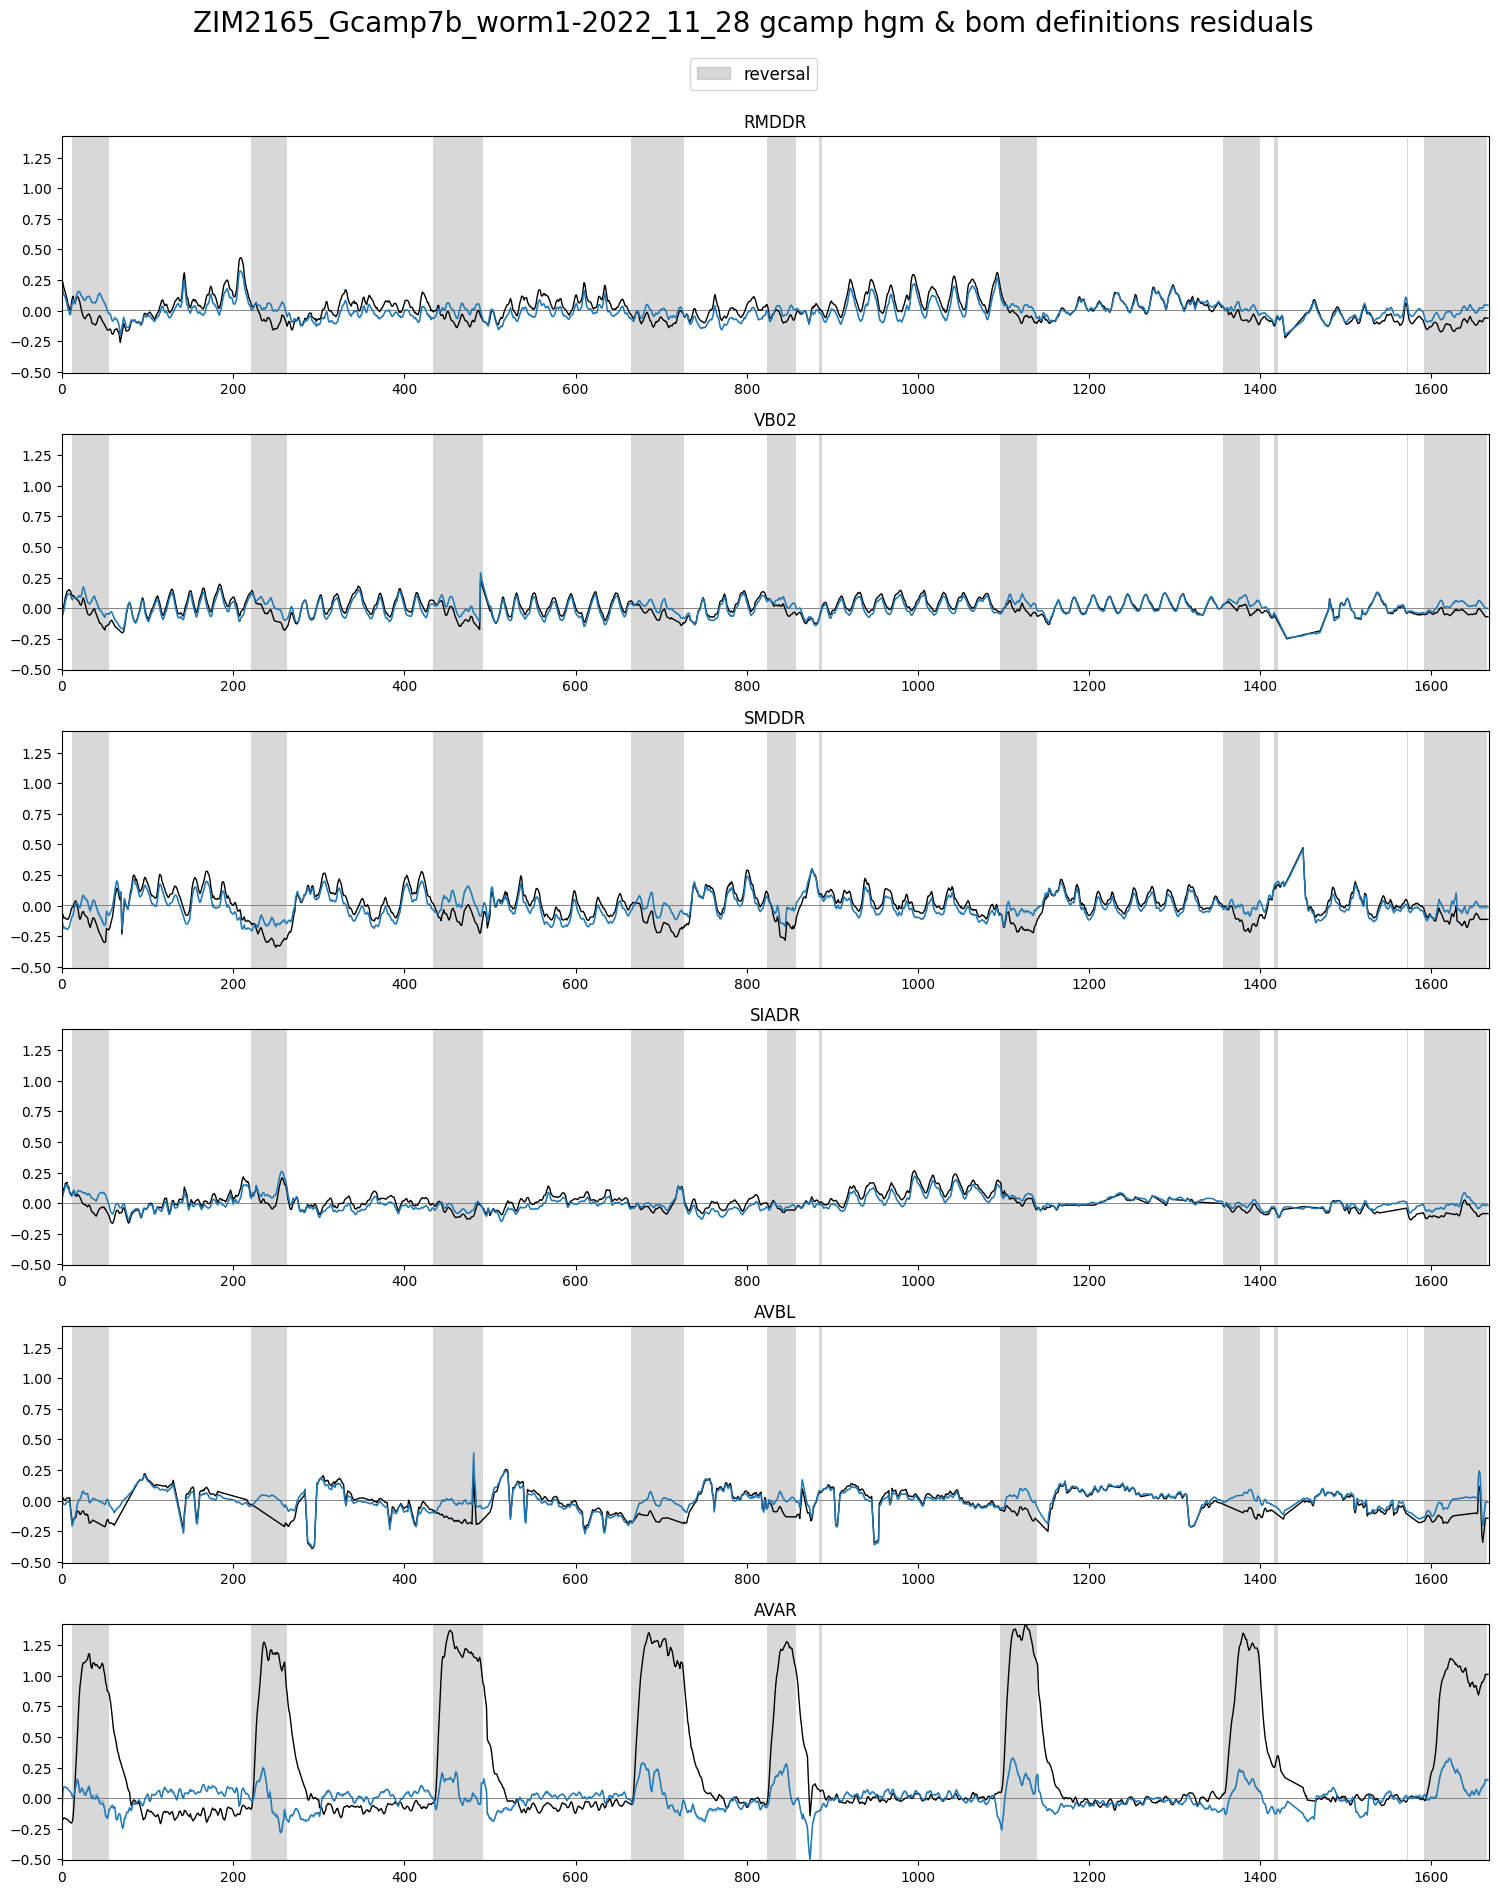

In [22]:
# max_x = 500
max_x = traces.values.shape[0]

plot_utils.plot_traces_splits(
	[hgm_res[0].loc[:max_x, neuron_labels]],
	[bom_res[0].loc[:max_x, neuron_labels]],
	traces.loc[:max_x, neuron_labels],
	discrete_states.loc[:max_x, ['REV']], label='reversal',
	title=f'{filename} gcamp hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_RES'

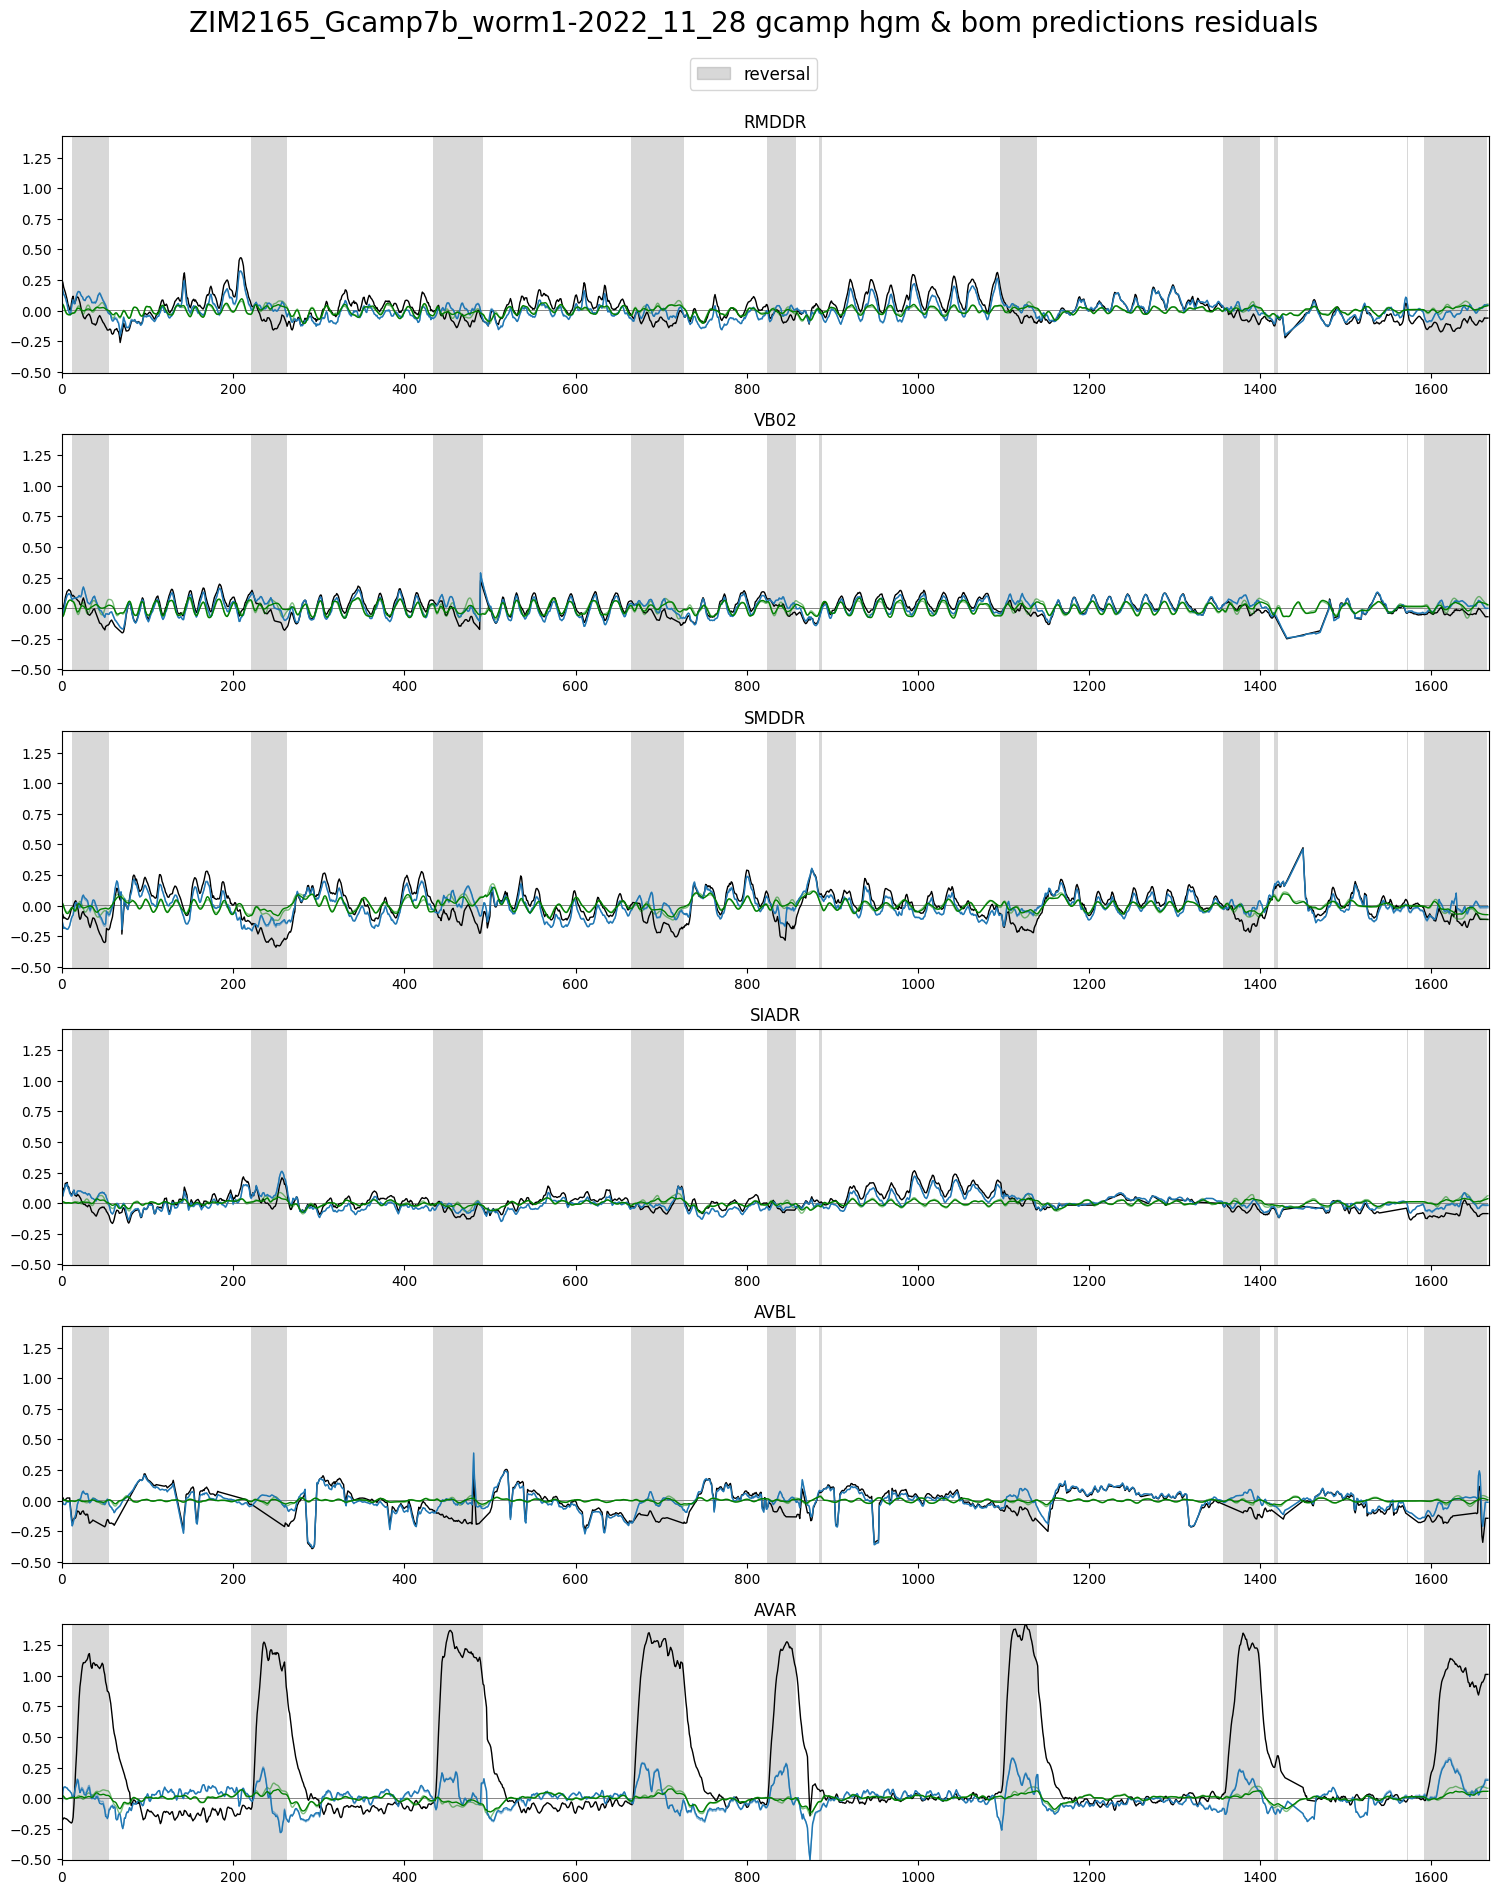

In [23]:
# max_x = 500
max_x = traces.values.shape[0]


plot_utils.plot_traces_splits_pairs(
	[hgm_res[0].loc[:max_x, neuron_labels],
	 hgm_pres[0].loc[:max_x, neuron_labels]],
	[bom_res[0].loc[:max_x, neuron_labels],
	 bom_pres[0].loc[:max_x, neuron_labels]],
	traces.loc[:max_x, neuron_labels],
	discrete_states.loc[:max_x, ['REV']], label='reversal',
	title=f'{filename} gcamp hgm & bom predictions residuals', ylimits=None, plots_per_row=1,
	save_path=None)  #../../out/plots/f'GCAMP_PRES_S{i}'

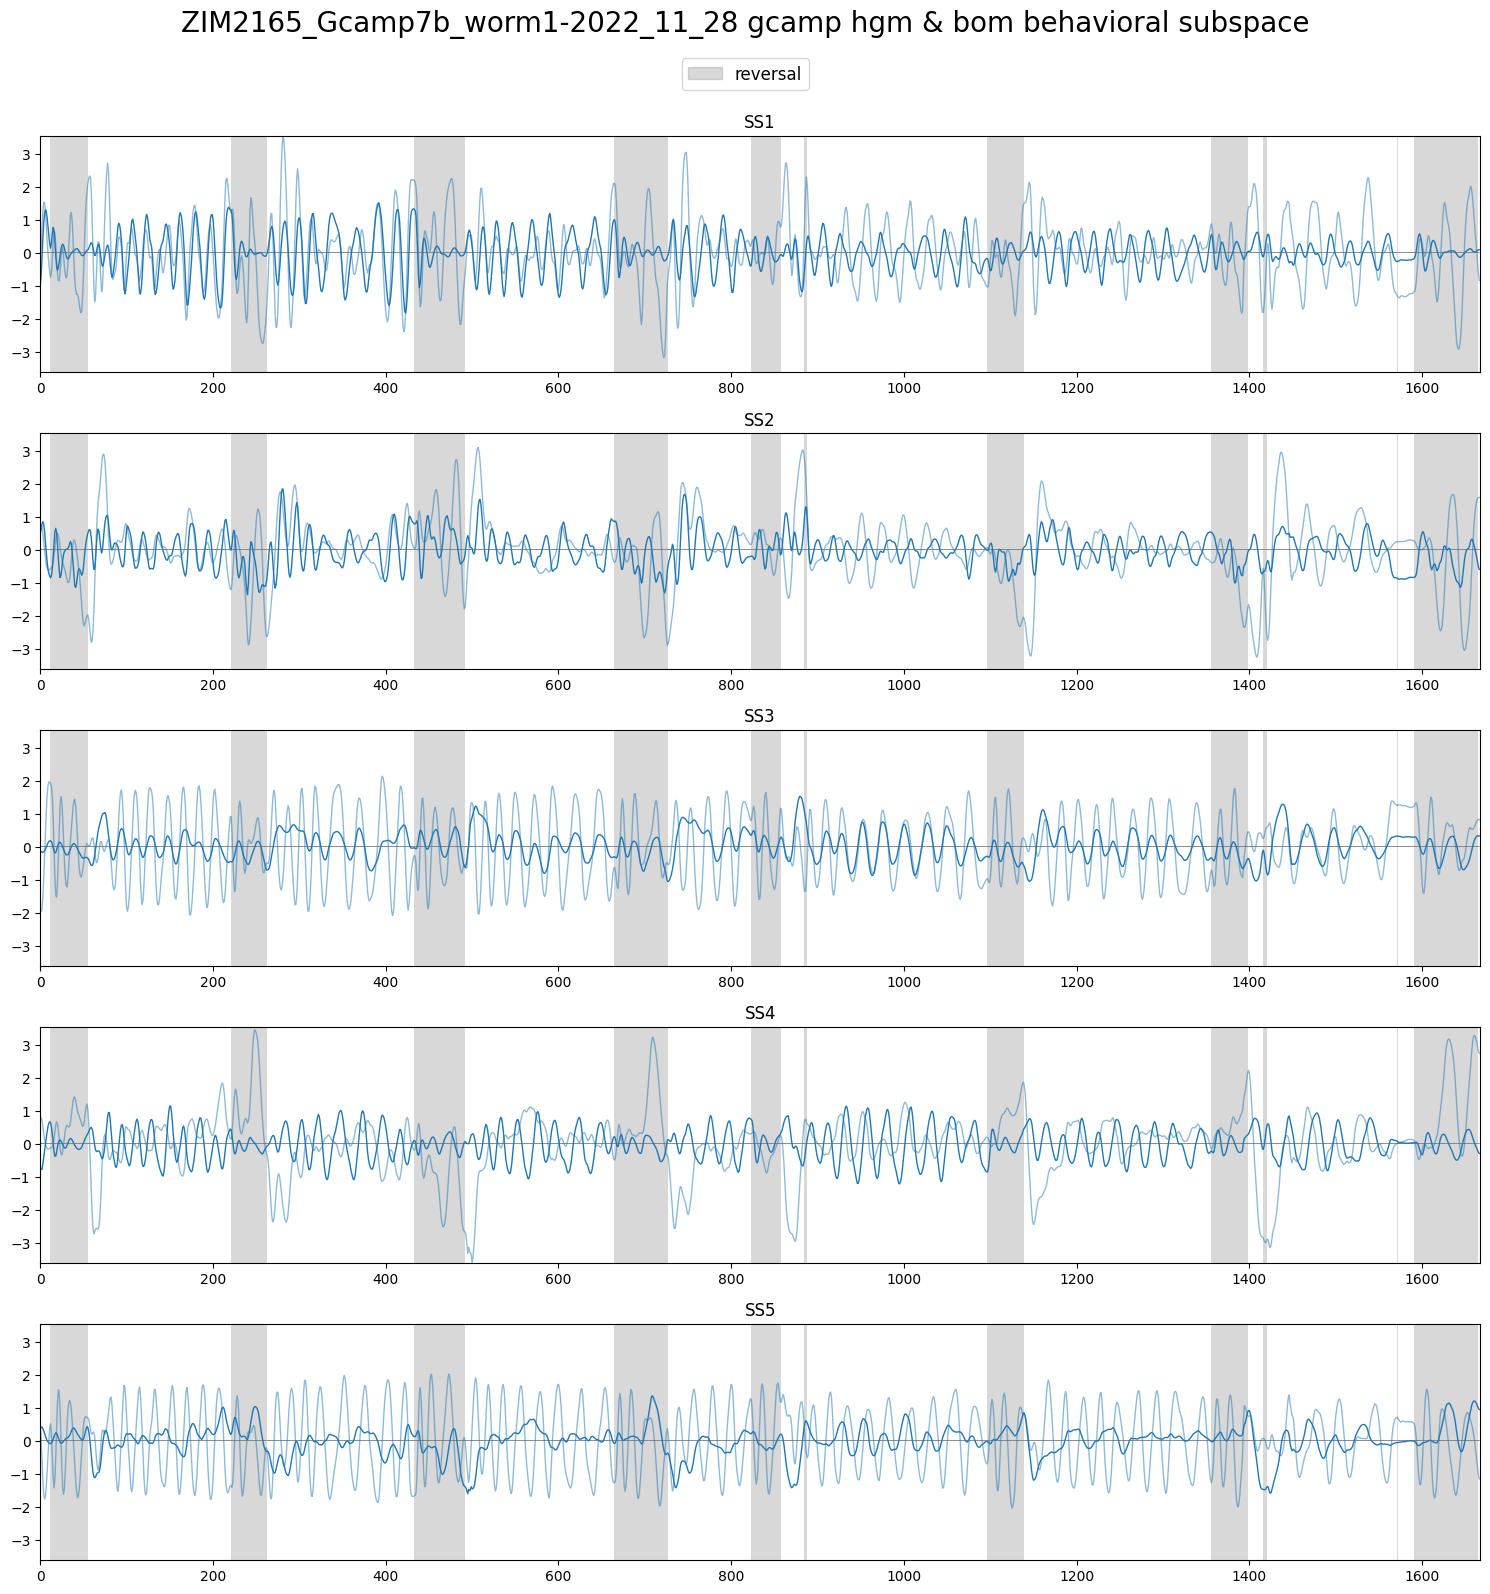

In [24]:
# max_x = 500
max_x = traces.values.shape[0]

plot_utils.plot_traces_splits(
	[hgm_bss[0].loc[:max_x]],
	[bom_bss[0].loc[:max_x]],
	None,
	discrete_states.loc[:max_x, ['REV']], label='reversal',
	title=f'{filename} gcamp hgm & bom behavioral subspace', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_RES'

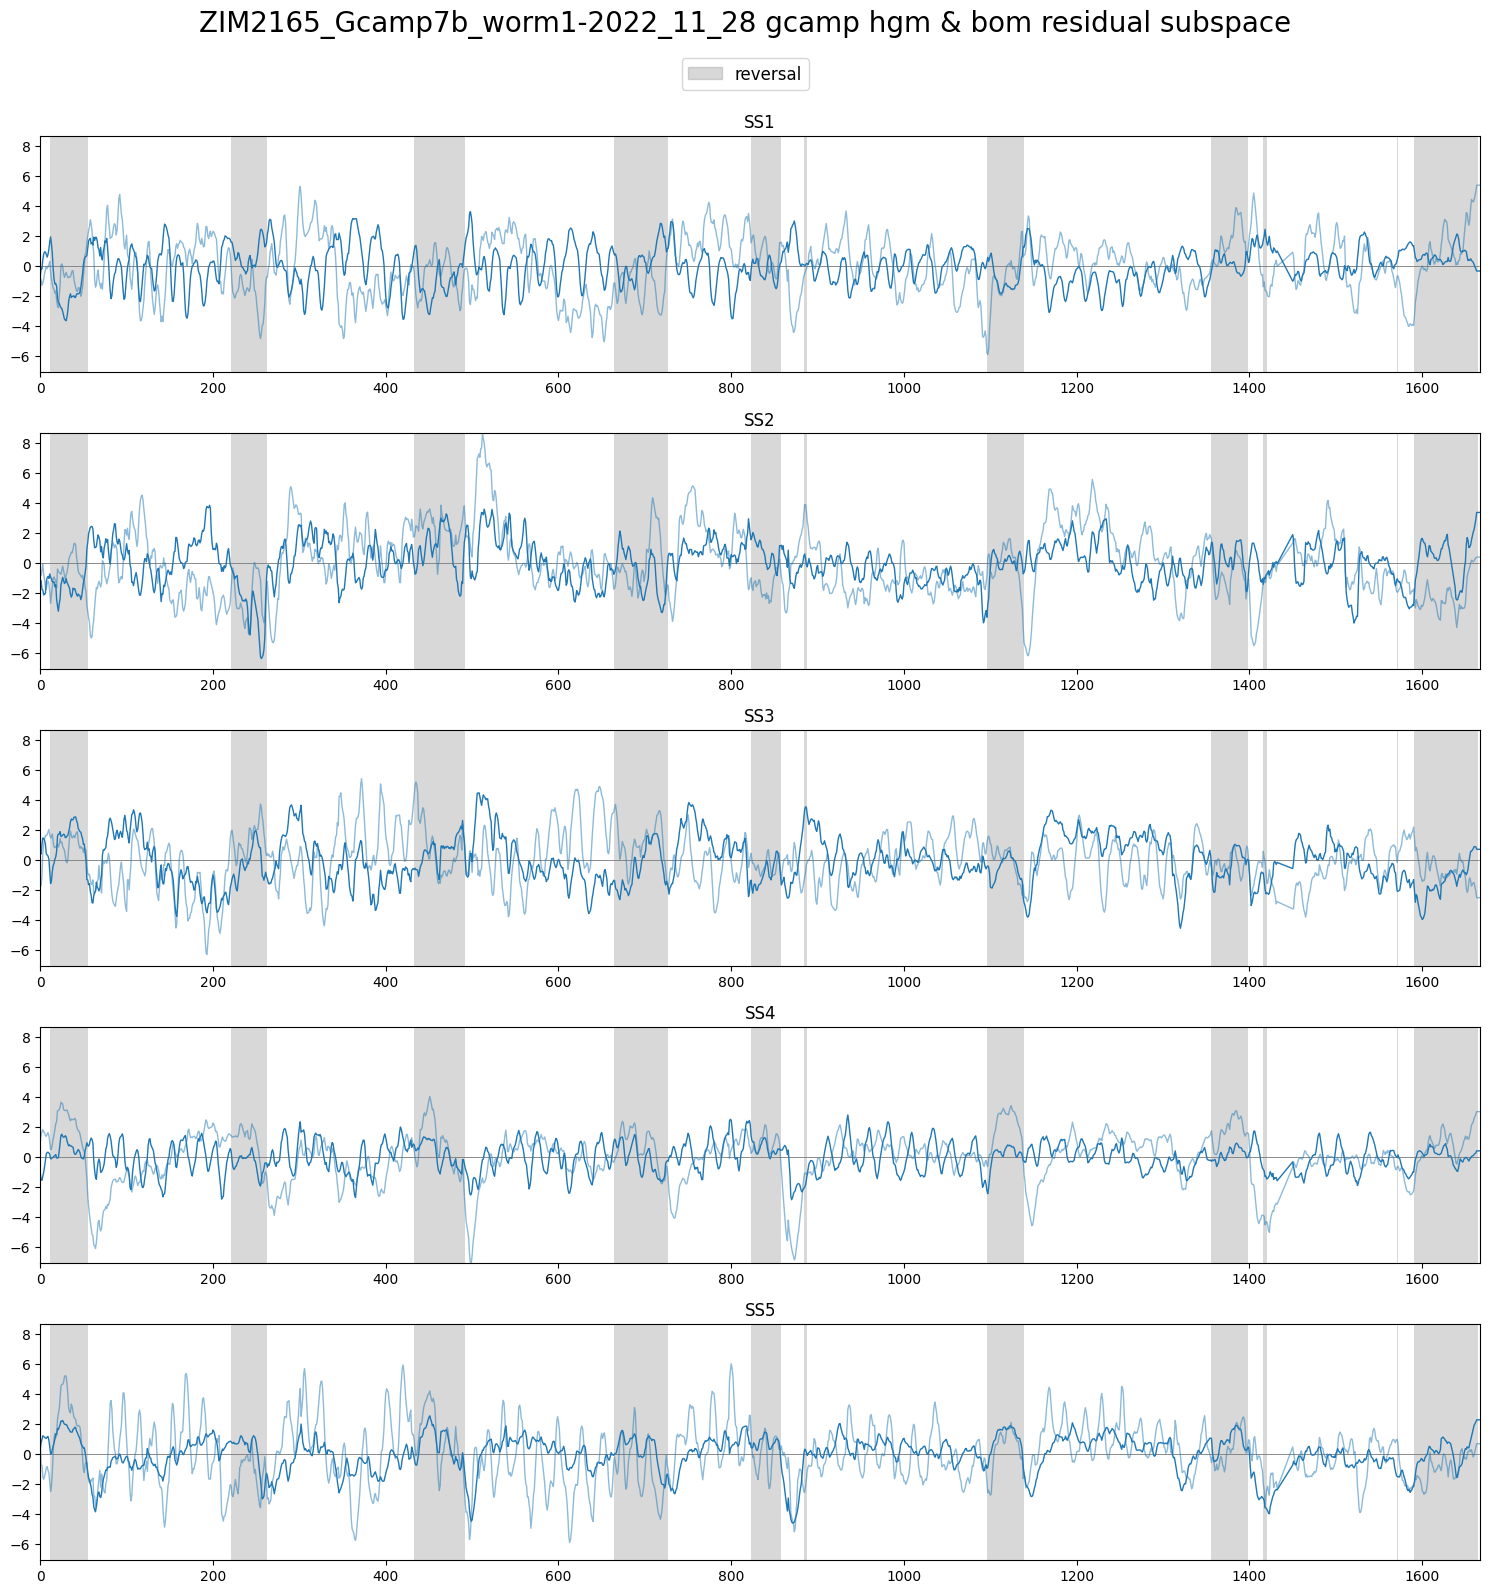

In [25]:
# max_x = 500
max_x = traces.values.shape[0]

plot_utils.plot_traces_splits(
	[hgm_resss[0].loc[:max_x]],
	[bom_resss[0].loc[:max_x]],
	None,
	discrete_states.loc[:max_x, ['REV']], label='reversal',
	title=f'{filename} gcamp hgm & bom residual subspace', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_RES'